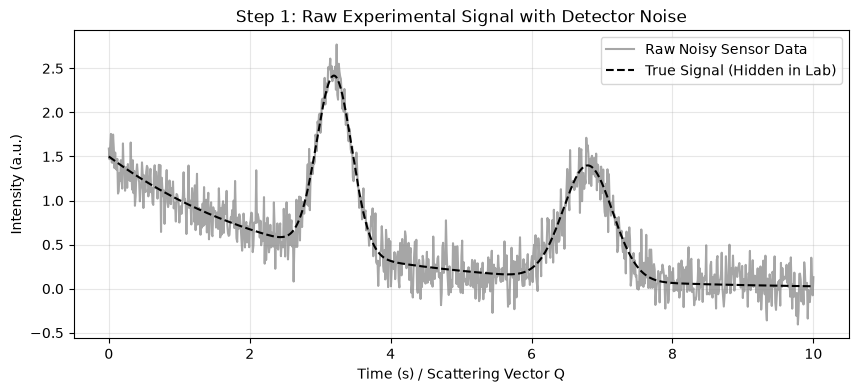

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter, find_peaks
from scipy.optimize import curve_fit

# Reproducibility kosam random seed
np.random.seed(42)

# Time / Q-range axis (0 nundi 10 seconds/units varaku 1000 points)
x = np.linspace(0, 10, 1000)

# True Physical Parameters (Veetini manam tarvata recover cheyali!)
true_tau = 2.5       # Decay constant (water absorption relaxation time)
true_peak1 = 3.2     # Peak 1 position
true_peak2 = 6.8     # Peak 2 position

# Clean physical signal = Exponential decay + 2 Gaussian peaks
decay_signal = 1.5 * np.exp(-x / true_tau)
peak1 = 2.0 * np.exp(-((x - true_peak1) ** 2) / (2 * 0.25 ** 2))
peak2 = 1.3 * np.exp(-((x - true_peak2) ** 2) / (2 * 0.35 ** 2))

clean_signal = decay_signal + peak1 + peak2

# Realistic detector noise add cheyadam
noise = np.random.normal(0, 0.18, size=x.shape)
raw_signal = clean_signal + noise

plt.figure(figsize=(10, 4))
plt.plot(x, raw_signal, label='Raw Noisy Sensor Data', color='gray', alpha=0.7)
plt.plot(x, clean_signal, label='True Signal (Hidden in Lab)', color='black', linestyle='--')
plt.title('Step 1: Raw Experimental Signal with Detector Noise')
plt.xlabel('Time (s) / Scattering Vector Q')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Detected Peak Positions: [3.193 6.817]
True Peak Positions:     [3.2, 6.8]


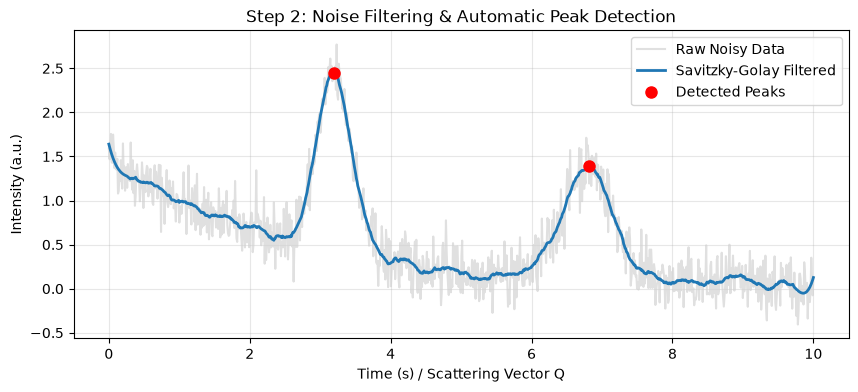

In [5]:
# 1. Savitzky-Golay filter tho noise smooth cheyadam (peaks shape padavakunda)
smoothed_signal = savgol_filter(raw_signal, window_length=51, polyorder=3)

# 2. Automatic ga peaks find cheyadam
peaks, properties = find_peaks(smoothed_signal, height=0.8, prominence=0.4, distance=50)

print(f"Detected Peak Positions: {x[peaks].round(3)}")
print(f"True Peak Positions:     [{true_peak1}, {true_peak2}]")

plt.figure(figsize=(10, 4))
plt.plot(x, raw_signal, label='Raw Noisy Data', color='lightgray', alpha=0.7)
plt.plot(x, smoothed_signal, label='Savitzky-Golay Filtered', color='#1f77b4', linewidth=2)
plt.plot(x[peaks], smoothed_signal[peaks], "ro", markersize=8, label='Detected Peaks')
plt.title('Step 2: Noise Filtering & Automatic Peak Detection')
plt.xlabel('Time (s) / Scattering Vector Q')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()



=== RECOVERED PHYSICAL PARAMETERS ===
Decay Constant (tau): 2.574 ± 0.068 (True: 2.5)
Peak 1 Center (mu1):  3.197 ± 0.005 (True: 3.2)
Peak 2 Center (mu2):  6.797 ± 0.009 (True: 6.8)


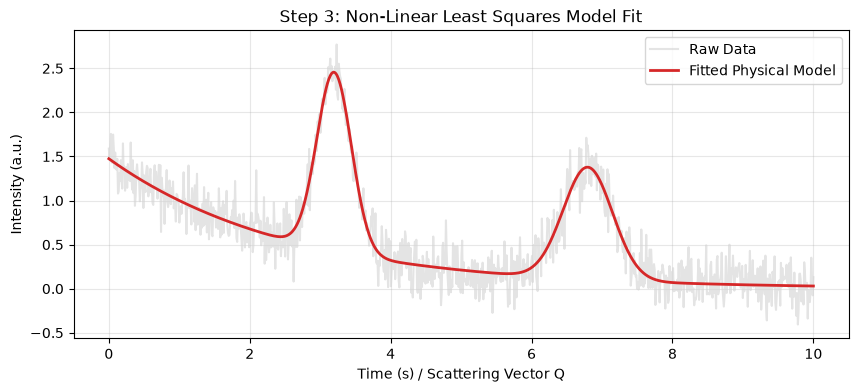

In [6]:
# Physical model function define cheyadam
def bluemat_model(x, A0, tau, A1, mu1, sigma1, A2, mu2, sigma2):
    decay = A0 * np.exp(-x / tau)
    g1 = A1 * np.exp(-((x - mu1) ** 2) / (2 * sigma1 ** 2))
    g2 = A2 * np.exp(-((x - mu2) ** 2) / (2 * sigma2 ** 2))
    return decay + g1 + g2

# Detected peaks nundi initial guesses ivvadam
initial_guess = [1.4, 2.0, 1.8, x[peaks[0]], 0.3, 1.2, x[peaks[1]], 0.3]

# Curve fitting run cheyadam
popt, pcov = curve_fit(bluemat_model, x, raw_signal, p0=initial_guess)
perr = np.sqrt(np.diag(pcov)) # Parameter uncertainties (DESY interviews lo chala important!)

fitted_signal = bluemat_model(x, *popt)

print("=== RECOVERED PHYSICAL PARAMETERS ===")
print(f"Decay Constant (tau): {popt[1]:.3f} ± {perr[1]:.3f} (True: {true_tau})")
print(f"Peak 1 Center (mu1):  {popt[3]:.3f} ± {perr[3]:.3f} (True: {true_peak1})")
print(f"Peak 2 Center (mu2):  {popt[6]:.3f} ± {perr[6]:.3f} (True: {true_peak2})")

plt.figure(figsize=(10, 4))
plt.plot(x, raw_signal, label='Raw Data', color='lightgray', alpha=0.6)
plt.plot(x, fitted_signal, label='Fitted Physical Model', color='#d62728', linewidth=2)
plt.title('Step 3: Non-Linear Least Squares Model Fit')
plt.xlabel('Time (s) / Scattering Vector Q')
plt.ylabel('Intensity (a.u.)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()



Goodness of Fit (R²): 0.9114
Residual Mean:        0.00194 (Should be ~0)
Residual Std Dev:     0.1759 (Expected Noise: 0.1800)


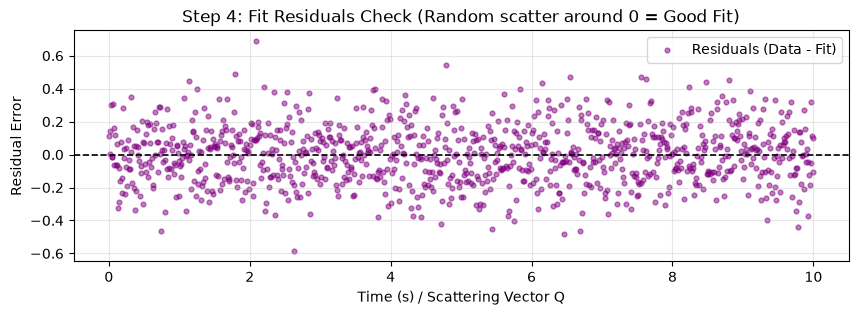

In [7]:
# Residuals = Actual Raw Data minus Fitted Model
residuals = raw_signal - fitted_signal

# R-squared (R2) calculate cheyadam (1.0 ki daggaraga unte fit chala accurate ani ardham)
ss_res = np.sum(residuals ** 2)
ss_tot = np.sum((raw_signal - np.mean(raw_signal)) ** 2)
r_squared = 1 - (ss_res / ss_tot)

print(f"Goodness of Fit (R²): {r_squared:.4f}")
print(f"Residual Mean:        {np.mean(residuals):.5f} (Should be ~0)")
print(f"Residual Std Dev:     {np.std(residuals):.4f} (Expected Noise: 0.1800)")

# Residuals Plot (Model miss ayina pattern emaina undha ani check cheyadaniki)
plt.figure(figsize=(10, 3))
plt.scatter(x, residuals, color='purple', alpha=0.5, s=12, label='Residuals (Data - Fit)')
plt.axhline(0, color='black', linestyle='--', linewidth=1.2)
plt.title('Step 4: Fit Residuals Check (Random scatter around 0 = Good Fit)')
plt.xlabel('Time (s) / Scattering Vector Q')
plt.ylabel('Residual Error')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
